In [2]:
import numpy as np
import pandas as pd
import sentence_transformers

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

import spacy

# SPACY_MODEL = 'en_core_web_sm' # or 'en_core_web_md'

C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df=pd.read_csv(Path.cwd().parent/'data'/'bbc-news-data.csv',sep='\t')

In [4]:
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


In [5]:
df=df.sample(n=1500,random_state=42)

In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 1500 entries, 414 to 970
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  1500 non-null   str  
 1   filename  1500 non-null   str  
 2   title     1500 non-null   str  
 3   content   1500 non-null   str  
dtypes: str(4)
memory usage: 58.6 KB


In [7]:
df.isna().sum() # nema nan vrednosti

category    0
filename    0
title       0
content     0
dtype: int64

In [8]:
df.duplicated().sum() # nema duplikata...

np.int64(0)

In [9]:
df.info() # category je target na kraju , filenam title i content su sve stringovi ..

<class 'pandas.DataFrame'>
Index: 1500 entries, 414 to 970
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  1500 non-null   str  
 1   filename  1500 non-null   str  
 2   title     1500 non-null   str  
 3   content   1500 non-null   str  
dtypes: str(4)
memory usage: 58.6 KB


In [10]:
df['article_text']=df['title']+ '. '+ df['content']

In [11]:
df.head()

,category,filename,title,content,article_text
414,business,415.txt,UK house prices dip in November,"UK house prices dipped slightly in November, ...",UK house prices dip in November. UK house pri...
420,business,421.txt,LSE 'sets date for takeover deal',The London Stock Exchange (LSE) is planning t...,LSE 'sets date for takeover deal'. The London...
1644,sport,332.txt,Harinordoquy suffers France axe,Number eight Imanol Harinordoquy has been dro...,Harinordoquy suffers France axe. Number eight...
416,business,417.txt,Barclays shares up on merger talk,Shares in UK banking group Barclays have rise...,Barclays shares up on merger talk. Shares in ...
1232,politics,337.txt,Campaign 'cold calls' questioned,Labour and the Conservatives are still teleph...,Campaign 'cold calls' questioned. Labour and ...


In [12]:
df.drop(columns='title',inplace=True)

In [13]:
df.drop(columns='content',inplace=True)

In [14]:
df.head()

,category,filename,article_text
414,business,415.txt,UK house prices dip in November. UK house pri...
420,business,421.txt,LSE 'sets date for takeover deal'. The London...
1644,sport,332.txt,Harinordoquy suffers France axe. Number eight...
416,business,417.txt,Barclays shares up on merger talk. Shares in ...
1232,politics,337.txt,Campaign 'cold calls' questioned. Labour and ...


In [15]:
#ispitati duzinu clanaka ...
df['article_length']=df.article_text.str.split(' ').str.len()

In [16]:
df.head()

,category,filename,article_text,article_length
414,business,415.txt,UK house prices dip in November. UK house pri...,408
420,business,421.txt,LSE 'sets date for takeover deal'. The London...,371
1644,sport,332.txt,Harinordoquy suffers France axe. Number eight...,348
416,business,417.txt,Barclays shares up on merger talk. Shares in ...,272
1232,politics,337.txt,Campaign 'cold calls' questioned. Labour and ...,586


In [17]:
df.article_length.describe()
#sbert model prima negde oko 256 tokena to je ... skraticemo tekst na 200 reci .. svakako po defaultu bert model odbacuje duzi deo i automatkski ga skrati ...

count    1500.000000
mean      386.290000
std       238.810395
min        92.000000
25%       248.000000
50%       333.000000
75%       477.250000
max      4490.000000
Name: article_length, dtype: float64

In [20]:
df.article_text=df.article_text.str.split(' ').str[:180].str.join(' ')

In [48]:
#ispitati duzinu skracenog  clanaka ...
df['article_reduced_length']=df.article_text_reduced.str.split(' ').str.len()

In [49]:
df.article_reduced_length.describe()

count    1500.00000
mean      178.18800
std         7.84315
min        92.00000
25%       180.00000
50%       180.00000
75%       180.00000
max       180.00000
Name: article_reduced_length, dtype: float64

In [50]:
df.head()

,category,filename,article_text,article_length,article_text_reduced,article_reduced_length
414,business,415.txt,UK house prices dip in November. UK house pri...,408,UK house prices dip in November. UK house pri...,180
420,business,421.txt,LSE 'sets date for takeover deal'. The London...,371,LSE 'sets date for takeover deal'. The London...,180
1644,sport,332.txt,Harinordoquy suffers France axe. Number eight...,348,Harinordoquy suffers France axe. Number eight...,180
416,business,417.txt,Barclays shares up on merger talk. Shares in ...,272,Barclays shares up on merger talk. Shares in ...,180
1232,politics,337.txt,Campaign 'cold calls' questioned. Labour and ...,586,Campaign 'cold calls' questioned. Labour and ...,180


In [23]:
from sentence_transformers import SentenceTransformer

In [24]:
model= SentenceTransformer('all-MiniLM-L12-v2')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2743.57it/s]


In [26]:
model=SentenceTransformer('Moj model',local_files_only=True)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2572.76it/s]


In [27]:
embedingproba=model.encode('ovo je proba')

In [28]:
embedingproba

array([-2.30642650e-02,  1.08896270e-01, -5.42045422e-02, -7.86459818e-03,
       -9.47552770e-02,  3.05046141e-03,  3.68701108e-02,  7.32303262e-02,
        5.95086887e-02, -1.93304792e-02,  4.69489954e-02, -9.96577367e-02,
       -1.73089057e-02, -5.28938882e-03, -4.10243869e-02, -1.11097684e-02,
        6.23134412e-02,  8.13044235e-02, -2.95195952e-02, -2.45384239e-02,
       -8.75522383e-03,  1.90974902e-02, -3.17195915e-02, -3.21595371e-02,
       -9.07099922e-04,  3.64515521e-02,  6.45801052e-02,  9.71925855e-02,
       -1.59134082e-02, -1.25396652e-02, -8.12356453e-03, -1.47799822e-02,
        7.84379393e-02,  1.58503698e-03, -5.41358367e-02,  5.47755025e-02,
       -8.94562155e-03, -3.42091322e-02, -1.79591980e-02,  4.71354201e-02,
       -7.07333954e-03, -7.19376281e-02, -1.24026269e-01, -2.08027139e-02,
        1.98909808e-02, -6.76047876e-02,  3.85549068e-02,  6.04005828e-02,
        2.70114169e-02,  5.51741011e-02,  5.30429790e-03, -6.74061775e-02,
       -7.70831294e-03,  

In [30]:
embeddings=model.encode(df['article_text'].to_numpy())

In [59]:
print(embeddings.shape) # 1500 reviewa je opisano preko 384 vektora ...

(1500, 384)


In [31]:
distance=1-cosine_similarity(embeddings,embeddings)

# kosinusna slicnost nam govori koliko su vektori slicni jedan izmedju drugih , ako je kosinusnalsicnost dva vektora 0.95 to znaci da su jako slicni , ali u zadatku klasterizacije razdaljina izmendju vektro se gleda preko distance koja ima drugacuju skalu sto je broj manji to su vektori blizi zato radimo 1-cosinusna slicnost i dobijamo za slicne vektore 0.05 . a za neke razlicite cija je kosinusnsa slicnost -1 tj da su oni skroz suprtini dobili bi ovde distance 2. znaci suprotno bas daleko ...iapk se sve ovo normalizujue na 0 - 1 skalu

{'icoord': [[35.0, 35.0, 45.0, 45.0],
  [25.0, 25.0, 40.0, 40.0],
  [15.0, 15.0, 32.5, 32.5],
  [5.0, 5.0, 23.75, 23.75],
  [65.0, 65.0, 75.0, 75.0],
  [55.0, 55.0, 70.0, 70.0],
  [95.0, 95.0, 105.0, 105.0],
  [85.0, 85.0, 100.0, 100.0],
  [62.5, 62.5, 92.5, 92.5],
  [14.375, 14.375, 77.5, 77.5],
  [115.0, 115.0, 125.0, 125.0],
  [145.0, 145.0, 155.0, 155.0],
  [135.0, 135.0, 150.0, 150.0],
  [175.0, 175.0, 185.0, 185.0],
  [165.0, 165.0, 180.0, 180.0],
  [205.0, 205.0, 215.0, 215.0],
  [195.0, 195.0, 210.0, 210.0],
  [172.5, 172.5, 202.5, 202.5],
  [142.5, 142.5, 187.5, 187.5],
  [120.0, 120.0, 165.0, 165.0],
  [225.0, 225.0, 235.0, 235.0],
  [245.0, 245.0, 255.0, 255.0],
  [265.0, 265.0, 275.0, 275.0],
  [250.0, 250.0, 270.0, 270.0],
  [230.0, 230.0, 260.0, 260.0],
  [285.0, 285.0, 295.0, 295.0],
  [305.0, 305.0, 315.0, 315.0],
  [290.0, 290.0, 310.0, 310.0],
  [245.0, 245.0, 300.0, 300.0],
  [142.5, 142.5, 272.5, 272.5],
  [45.9375, 45.9375, 207.5, 207.5],
  [335.0, 335.0, 345.0, 34

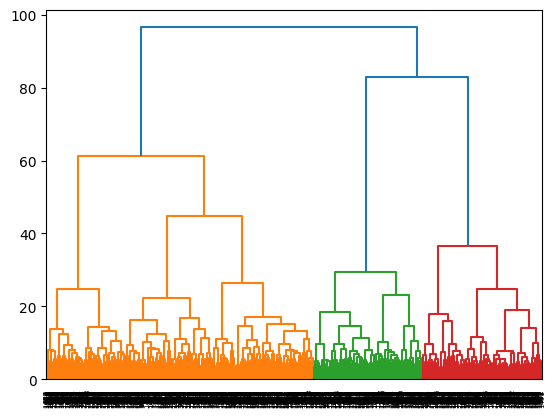

In [32]:

sch.dendrogram(sch.linkage(distance,method='ward'))

In [ ]:
# na osnovu dendograma mozemo da kazmeo da je optimalno od 2 do 5 klastera

In [63]:
dist_clipped=np.clip(distance,0,None)

In [65]:
for k in range(2,6):
    klasteri=sch.fcluster(sch.linkage(distance,method='ward'),t=k,criterion='maxclust')
    print(k,round(silhouette_score(dist_clipped,klasteri,metric='precomputed'),4))

2 0.0721
3 0.0761
4 0.0937
5 0.1017


In [ ]:
# vidimo da trebamo da podelimo na 5 delova ..

In [66]:
N_clusters=5
optimal_clusterning=sch.fcluster(sch.linkage(distance,method='ward'),t=N_clusters,criterion='maxclust')

In [67]:
df['cluster']=optimal_clusterning

In [68]:
df.head()

,category,filename,article_text,article_length,article_text_reduced,article_reduced_length,cluster
414,business,415.txt,UK house prices dip in November. UK house pri...,408,UK house prices dip in November. UK house pri...,180,4
420,business,421.txt,LSE 'sets date for takeover deal'. The London...,371,LSE 'sets date for takeover deal'. The London...,180,3
1644,sport,332.txt,Harinordoquy suffers France axe. Number eight...,348,Harinordoquy suffers France axe. Number eight...,180,5
416,business,417.txt,Barclays shares up on merger talk. Shares in ...,272,Barclays shares up on merger talk. Shares in ...,180,3
1232,politics,337.txt,Campaign 'cold calls' questioned. Labour and ...,586,Campaign 'cold calls' questioned. Labour and ...,180,4


In [69]:
print(df['cluster'].value_counts())

cluster
5    361
4    329
3    305
2    265
1    240
Name: count, dtype: int64


In [ ]:
#vidim da je generalno podela sasvim korektna ...

In [70]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [72]:
custom_stop_words=set(ENGLISH_STOP_WORDS)


In [74]:
custom_stop_words.discard('not')

In [84]:
#top 10 reci ..
keyword_extractor=TfidfVectorizer(stop_words='english',ngram_range=(2,2),min_df=0.01,max_df=0.95)

In [85]:
def get_cluster_keywords(cluster):
    tekst=df[df['cluster']==cluster].article_text_reduced
    tfidf=keyword_extractor.fit_transform(tekst)
    #izvuces keywords iz tacno tog clustera
    proseci=tfidf.mean(axis=0).A1
    reci=keyword_extractor.get_feature_names_out()
    rezultat=pd.Series(proseci,index=reci)
    return rezultat.nlargest(10).items()   # ovde treba na krjau items i radi lepo sa profesorkinim kodom tamo ne treba nista da se menja onda ...

KeyError: 'cluster'

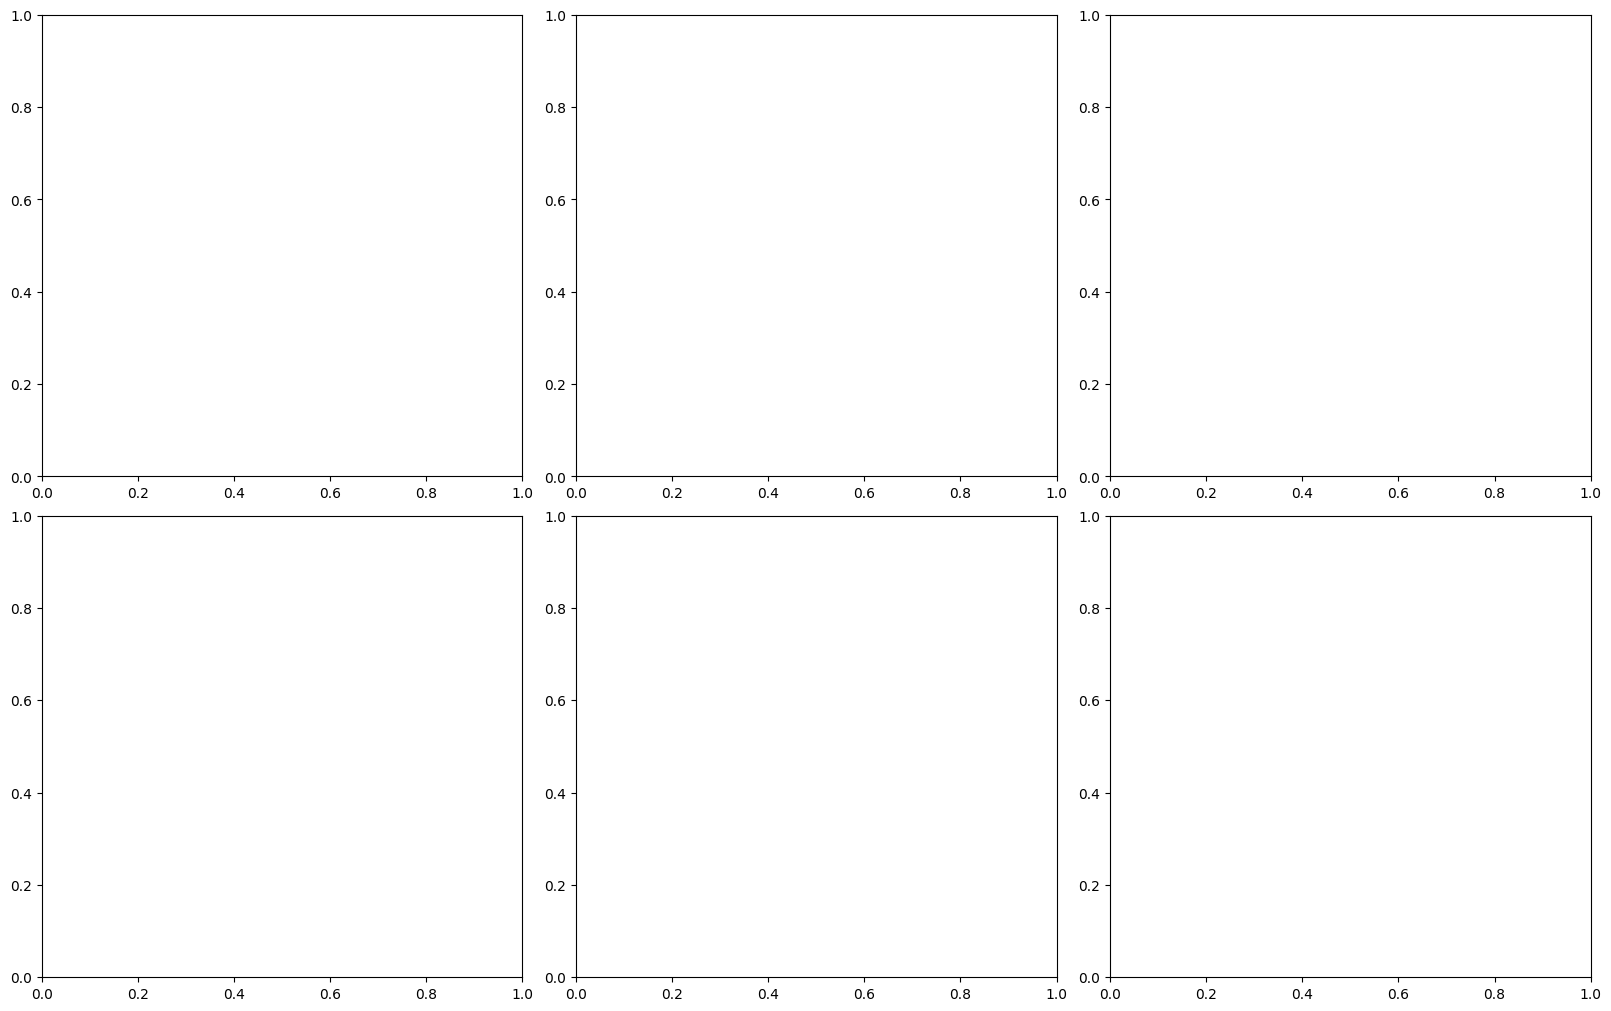

In [33]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=2, ncols=3, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = df['cluster'].nunique()
for i in range(n_clust):

    scored_kwds = get_cluster_keywords(i+1)
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i+1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

# # zs slucaj da je kreirano vise plotova nego sto je potrebno za prikaz (npr. grid 2x2, za prikaz 3 klastera)
# axes[n_clust-1].remove()

fig.suptitle("Keywords across the news clusters")

plt.show()

In [80]:
df.category.value_counts()

category
business         367
sport            350
politics         269
entertainment    258
tech             256
Name: count, dtype: int64

In [89]:
# Unakrsna tabela: redovi su stvarne rubrike, kolone su tvoji klasteri
tabela_poklapanja = pd.crosstab(df['category'], df['cluster'], margins=True, margins_name="Ukupno")
print(tabela_poklapanja)

cluster        business  entertainment  politics  sport  tech  Ukupno
category                                                             
business            290              2        56      7    12     367
entertainment         3            230         9      0    16     258
politics              2              1       263      0     3     269
sport                 0              0         0    350     0     350
tech                 10              7         1      4   234     256
Ukupno              305            240       329    361   265    1500
